# Model B, B0 — where do humans stop? (Oct 30, 2026)

**Spec (descriptive only; given before results):**

TASK (Model B, data check B0): where do humans stop? Descriptive only. G-train only
(G-val stays clean for later choices between model versions). Never load Ring/CT.
No simulation, no changes to src/slider (new helpers go in the notebook or a new file).

DATA: the same runs and human seats as P17 (load_runs("behavior"), G-train, whole-second
files out). Use motion.py's F1b classification as it is: moving steps, stops (a counted
moving step followed by a halt), steps into the wall excluded.
Per-step stop chance = stops / counted moving steps.

1. LABEL EVERY COUNTED MOVING STEP
   Causal labels only (what a simulator could know at that moment). "End band" =
   |s| >= 0.9 (on old CL use hazard.py's |k| >= 9).
   - phase:
     - first_trip = the player has not yet reached any end band in this round;
     - outbound = the player has left an end band and has not reached an end band since.
   - progress = the position along the direction of travel: s \* phi, binned in 0.1 steps
     from -0.9 to +0.9 (negative = still on the side it came from, positive = past the middle).
   - reversed = 1 if the player has reversed since the phase began.

   Also one outcome-based label, for description only (it uses the future):
   - completed crossing = an outbound segment that reaches the opposite end band;
   - aborted excursion = an outbound segment that returns to the same end band;
   - censored = the round ended first.

2. TABLE results/tables/pB0_stop_by_state.csv. Per interface (lab v09, old CL, CC) and pooled:
   - stop chance per step, number of steps, number of stops, group-bootstrap 95% CI
     (1,000 resamples, stratified by dataset, seed 573)
   - for each of these cells: (a) first_trip vs. outbound; (b) outbound split by reversed (0/1);
     (c) outbound split by outcome (completed crossing / aborted excursion / censored);
     (d) all moving steps (this must reproduce P17's per-step lam_stop\*dt, as a check).
   - the share of all moving steps in each cell.
   - for completed crossings: the share that are pause-free (no stop at all).

3. FIGURE results/figures/pB0_stop_by_position.png. Stop chance per step vs. progress
   (x from -0.9 to +0.9), one panel per interface. Lines: first_trip, outbound (reversed = 0),
   outbound (reversed = 1). 95% CI bands. Mark the overall average (P17) as a horizontal dashed line.

4. This notebook: spec cell first, short cells, a 2-3 line "how to read it" under the table and the figure.

## Choices the spec leaves open

Fixed in `src/slider/stop_states.py` (a new file; no existing file changed) before any table was made.

- **Steps and stops** are recomputed row by row with the same tests as `motion.motion_spells` (F1b), and checked against it seat by seat below. A row with |Δs| holds k = max(1, round(|Δs| / step)) steps; it is split into k steps at evenly spaced positions from the old s to the new s. A stop belongs to the last step of its row.
- **Phase** is set by every own step (counted, mid-event or at the wall), from the position it lands on. A counted step that lands in an end band (but not on the wall) is a third phase, **in_band**: it is neither first_trip nor outbound. It is in the table so that the shares add up to 1, and left out of the figure.
- **phi** (direction of travel) is fixed for the whole phase: first_trip = the sign of the seat's first own move (in s, also on old CL); outbound = away from the band it left. So progress is the position seen from where the phase started, and after a reversal it can run backwards.
- **reversed** = a confirmed reversal (`detect_events`, m = 2; probes do not count) that starts after the phase's first row. The turn that takes the player out of the band starts at or before that row, so it does not count.
- **Pause-free share** is over completed crossings with at least one counted step (no CI; the spec asks for the share only).
- **Bootstrap:** `motion.boot_ratios` as in P17: per interface its own groups, pooled all 39 groups, drawn within EL / CL / CC, 1,000 resamples, seed 573. A cell that is empty in some resample gets no CI (NaN).
- **Figure:** bins with fewer than 30 steps are not drawn.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from slider import config, motion, stop_states
from slider import slider_logs as sl

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

runs, table = sl.load_runs("behavior")                  # roles={"train"}: G-train only, no G-val, Ring or CT
assert set(table["role"]) == {"train"}
steps = stop_states.step_table(runs)
print(len(runs), "rounds,", table["file"].nunique(), "groups,", len(steps), "counted moving steps,",
      int(steps["stop"].sum()), "stops")

244 rounds, 39 groups, 92320 counted moving steps, 29114 stops


## Check: the same steps and stops as motion.py (F1b), seat by seat

In [2]:
seats, _ = motion.motion_table(runs)
mine = steps.groupby(["file", "wave", "player"]).agg(stops_b0=("stop", "sum"), moving_b0=("dt", "sum"))
both = seats.set_index(["file", "wave", "player"])[["stops", "moving_s"]].join(mine).fillna(0)
assert (both["stops"] == both["stops_b0"]).all() and np.allclose(both["moving_s"], both["moving_b0"])
print(len(both), "seats: stops and moving seconds equal motion_spells for every seat")

1662 seats: stops and moving seconds equal motion_spells for every seat


## Labels: cells and progress bins

In [3]:
CELLS = [("(d) all", "all moving steps", lambda d: np.ones(len(d), bool)),
         ("(a) phase", "first_trip", lambda d: d["phase"] == "first_trip"),
         ("(a) phase", "outbound", lambda d: d["phase"] == "outbound"),
         ("(a) phase", "in_band (not in spec)", lambda d: d["phase"] == "in_band"),
         ("(b) outbound x reversed", "reversed = 0", lambda d: (d["phase"] == "outbound") & (d["reversed"] == 0)),
         ("(b) outbound x reversed", "reversed = 1", lambda d: (d["phase"] == "outbound") & (d["reversed"] == 1)),
         ("(c) outbound x outcome", "completed crossing", lambda d: d["outcome"] == "completed"),
         ("(c) outbound x outcome", "aborted excursion", lambda d: d["outcome"] == "aborted"),
         ("(c) outbound x outcome", "censored", lambda d: d["outcome"] == "censored")]
LINES = {"first_trip": lambda d: d["phase"] == "first_trip",
         "outbound, reversed = 0": lambda d: (d["phase"] == "outbound") & (d["reversed"] == 0),
         "outbound, reversed = 1": lambda d: (d["phase"] == "outbound") & (d["reversed"] == 1)}
BINS = np.round(np.arange(-0.9, 0.9, 0.1), 1) + 0.0            # left edges, 18 bins of 0.1
steps["bin"] = np.round(np.floor(np.round((steps["progress"] + 0.9) * 10, 6)) / 10 - 0.9, 1) + 0.0   # + 0.0: no -0.0
assert steps["bin"].dropna().between(-0.9, 0.8).all()


def add_counts(d, masks):
    """d with columns n<i> (1 if the step is in mask i) and y<i> (1 if it is also a stop)."""
    cols = {}
    for i, mask in enumerate(masks):
        cols[f"n{i}"] = np.asarray(mask, int)
        cols[f"y{i}"] = cols[f"n{i}"] * d["stop"].to_numpy()
    return pd.concat([d, pd.DataFrame(cols, index=d.index)], axis=1)

## Table: stop chance per step by state (95% CI: 1,000 stratified group resamples, seed 573)

In [4]:
def cell_table(d, name):
    masks = [f(d) for _, _, f in CELLS]
    x = add_counts(d, masks)
    with np.errstate(invalid="ignore", divide="ignore"):
        low, high = motion.boot_ratios(x, [(f"y{i}", f"n{i}") for i in range(len(CELLS))])
    out = []
    for i, (group, cell, _) in enumerate(CELLS):
        n, y = int(x[f"n{i}"].sum()), int(x[f"y{i}"].sum())
        out.append({"interface": name, "group": group, "cell": cell, "steps": n, "stops": y,
                    "stop_chance": y / n if n else np.nan, "ci_low": low[i], "ci_high": high[i],
                    "share_of_steps": n / len(d)})
    seg = d[d["outcome"] == "completed"].groupby(["file", "wave", "player", "segment"])["stop"].sum()
    out[6].update(crossings=len(seg), pause_free=int((seg == 0).sum()), pause_free_share=(seg == 0).mean())
    return out


rows = [r for name, d in motion.by_interface(steps) for r in cell_table(d, name)]
b0 = pd.DataFrame(rows).replace({"interface": {"shared": "pooled"}})
b0.to_csv(config.TABLES / "pB0_stop_by_state.csv", index=False)
b0.round(4)

,interface,group,cell,steps,stops,stop_chance,ci_low,ci_high,share_of_steps,crossings,pause_free,pause_free_share
0,lab_v09,(d) all,all moving steps,32513,10974,0.3375,0.2967,0.3739,1.0000,NaN,NaN,NaN
1,lab_v09,(a) phase,first_trip,5596,2464,0.4403,0.4008,0.4753,0.1721,NaN,NaN,NaN
2,lab_v09,(a) phase,outbound,24723,7776,0.3145,0.2689,0.3547,0.7604,NaN,NaN,NaN
3,lab_v09,(a) phase,in_band (not in spec),2194,734,0.3345,0.2814,0.3867,0.0675,NaN,NaN,NaN
4,lab_v09,(b) outbound x reversed,reversed = 0,21885,6232,0.2848,0.2428,0.3225,0.6731,NaN,NaN,NaN
5,lab_v09,(b) outbound x reversed,reversed = 1,2838,1544,0.5440,0.4726,0.6139,0.0873,NaN,NaN,NaN
6,lab_v09,(c) outbound x outcome,completed crossing,20422,5482,0.2684,0.2240,0.3095,0.6281,1267.0,557.0,0.4396
7,lab_v09,(c) outbound x outcome,aborted excursion,4300,2293,0.5333,0.4489,0.6070,0.1323,NaN,NaN,NaN
8,lab_v09,(c) outbound x outcome,censored,1,1,1.0000,NaN,NaN,0.0000,NaN,NaN,NaN
9,old_cl,(d) all,all moving steps,18975,3423,0.1804,0.1747,0.1919,1.0000,NaN,NaN,NaN


**How to read it.** `stop_chance` is the chance that a counted moving step is followed by a stop (a halt in halted time); `share_of_steps` is the cell's share of the interface's moving steps, so the three (a) rows add up to 1. (b) and (c) split the outbound row two ways. `pause_free_share` (on the completed-crossing row) is the share of completed crossings with no stop at all. Old CL has 2 groups, so its CIs are crude.

## Check (d): the all-steps row reproduces P17's per-step lam_stop \* dt

In [5]:
p17 = pd.read_csv(config.P17_RATES).query("rate == 'lam_stop'").set_index("interface")
d = b0[b0["cell"] == "all moving steps"].set_index("interface").rename(index={"pooled": "shared"})
chk = pd.DataFrame({"P17 stops": p17["events"], "B0 stops": d["stops"], "P17 moving_s": p17["exposure_s"],
                    "B0 steps": d["steps"], "P17 lam_stop": p17["estimate"]})
chk["mean dt per step"] = chk["P17 moving_s"] / chk["B0 steps"]      # one dt per round; old CL: 0.1 s
chk["P17 lam_stop * dt"] = chk["P17 lam_stop"] * chk["mean dt per step"]
chk["B0 stop chance"] = d["stop_chance"]
assert (chk["P17 stops"] == chk["B0 stops"]).all() and np.allclose(chk["P17 lam_stop * dt"], chk["B0 stop chance"])
chk.round(5)

,P17 stops,B0 stops,P17 moving_s,B0 steps,P17 lam_stop,mean dt per step,P17 lam_stop * dt,B0 stop chance
interface,,,,,,,,
lab_v09,10974,10974,3367.25000,32513,3.25904,0.10357,0.33753,0.33753
old_cl,3423,3423,1897.50000,18975,1.80395,0.10000,0.18040,0.18040
cc,14717,14717,1325.68621,40832,11.10142,0.03247,0.36043,0.36043
shared,29114,29114,6590.43621,92320,4.41761,0.07139,0.31536,0.31536


dt differs between rounds inside lab v09 and CC, so "lam_stop \* dt" uses the step-weighted mean dt (P17's moving seconds / steps). Then lam_stop \* dt = stops / steps exactly; old CL has one dt (0.1 s).

## Stop chance by progress

In [6]:
def line_table(d, name, min_steps=30):
    keys = [(line, b) for line in LINES for b in BINS]
    masks = [LINES[line](d) & (d["bin"] == b) for line, b in keys]
    x = add_counts(d, masks)
    with np.errstate(invalid="ignore", divide="ignore"):
        low, high = motion.boot_ratios(x, [(f"y{i}", f"n{i}") for i in range(len(keys))])
    out = pd.DataFrame([{"interface": name, "line": line, "bin": b, "x": b + 0.05,
                         "steps": int(x[f"n{i}"].sum()), "stops": int(x[f"y{i}"].sum()),
                         "ci_low": low[i], "ci_high": high[i]} for i, (line, b) in enumerate(keys)])
    out["stop_chance"] = out["stops"] / out["steps"].replace(0, np.nan)
    return out[out["steps"] >= min_steps]


lines = pd.concat([line_table(d, name) for name, d in motion.by_interface(steps) if name != "shared"])
lines.pivot_table(index=["interface", "line"], columns="bin", values="steps", fill_value=0).astype(int)

bin                               -0.9  -0.8  -0.7  -0.6  -0.5  -0.4  -0.3  -0.2  -0.1   0.0   0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8
interface line                                                                                                                              
cc        first_trip                 0   134   136   137   148   154   160   175   118    95  1010   934   885   859   839   811   803   798
          outbound, reversed = 0     0     0  1931  1920  1874  1844  1819  1790  1771  1748  1727  1709  1692  1678  1668  1661  1651  1634
          outbound, reversed = 1     0   210   191   170   150   142   125   105    90    84    73    69    68    58    46    38    36    40
lab_v09   first_trip                 0    95    99   100   105   111   114   118    85    79   682   633   610   590   567   546   537   525
          outbound, reversed = 0     0     0  1238  1643  1580  1520  1472  1431  1406  1380  1347  1317  1303  1283  1268  1253  1231  1213
          outbound, reversed = 1     0   322   276   228   211   211   196   182   165   176   154   145   139   114    95    76    74    74
old_cl    first_trip                40   100   105   123   115   131   141   147   172   462   489   448   415   388   354   338   334   205
          outbound, reversed = 0   179   788   780   752   671   634   597   584   590   561   536   516   486   478   467   469   454   269
          outbound, reversed = 1    98   244   212   198   190   181   169   156   142   130    94    90    83    99    91    85    87    43

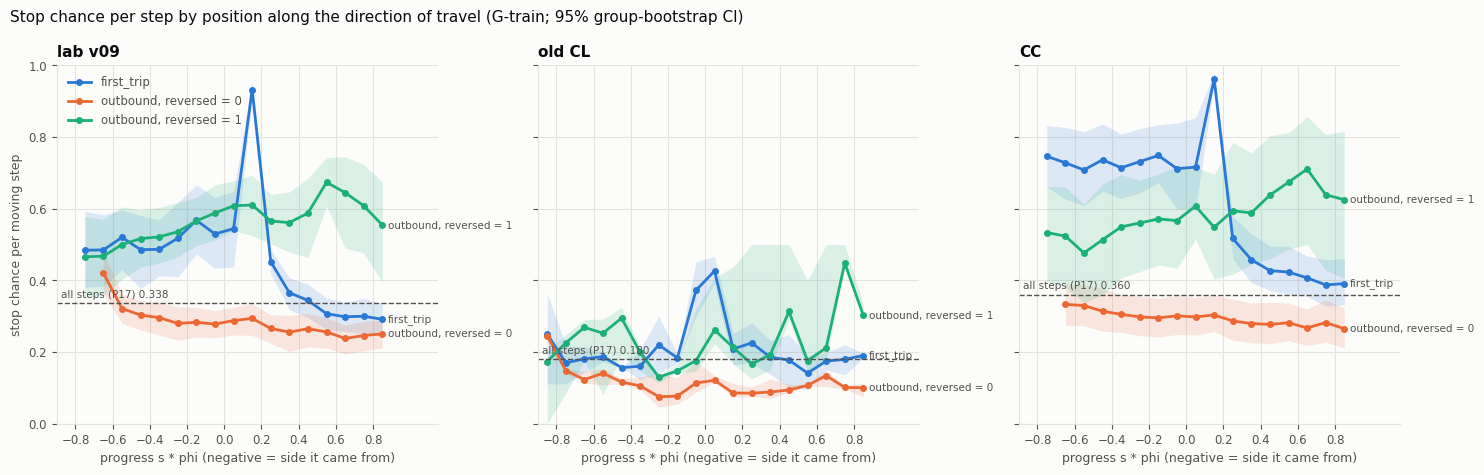

In [7]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = dict(zip(LINES, ["#2a78d6", "#eb6834", "#1baf7a"]))
NAMES = {"lab_v09": "lab v09", "old_cl": "old CL", "cc": "CC"}
avg = b0[b0["cell"] == "all moving steps"].set_index("interface")["stop_chance"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), facecolor=SURFACE, sharey=True)
for ax, name in zip(axes, motion.INTERFACES):
    for line, color in COLORS.items():
        x = lines[(lines["interface"] == name) & (lines["line"] == line)]
        ax.fill_between(x["x"], x["ci_low"], x["ci_high"], color=color, alpha=0.15, linewidth=0)
        ax.plot(x["x"], x["stop_chance"], color=color, linewidth=2, marker="o", markersize=4, label=line)
        ax.annotate(line, (x["x"].iloc[-1], x["stop_chance"].iloc[-1]), xytext=(4, 0), textcoords="offset points",
                    fontsize=7.5, color=INK_2, va="center")
    ax.axhline(avg[name], color=INK_2, linewidth=1, linestyle="--")
    ax.annotate(f"all steps (P17) {avg[name]:.3f}", (-0.88, avg[name]), xytext=(0, 4), textcoords="offset points",
                fontsize=7.5, color=INK_2)
    ax.set_xlim(-0.9, 1.15)
    ax.set_xticks(np.round(np.arange(-0.8, 0.81, 0.2), 1))
    ax.set_ylim(0, 1)
    ax.set_title(NAMES[name], loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.set_xlabel("progress s * phi (negative = side it came from)", color=INK_2, fontsize=9)
    ax.set_facecolor(SURFACE)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=INK_2, labelsize=8.5)
axes[0].set_ylabel("stop chance per moving step", color=INK_2, fontsize=9)
axes[0].legend(frameon=False, fontsize=8.5, labelcolor=INK_2, loc="upper left")
fig.suptitle("Stop chance per step by position along the direction of travel (G-train; 95% group-bootstrap CI)",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig(config.FIGURES / "pB0_stop_by_position.png", dpi=150, facecolor=SURFACE)
plt.show()

**How to read it.** Each point is the chance that a counted moving step landing in that 0.1 bin of progress is followed by a stop; bands are 95% group-bootstrap CIs, the dashed line is the interface's all-steps average (P17). Progress runs from where the phase started (left) to the far end (right); first_trip starts at the middle (0), outbound at the band it left (on lab v09 and CC the first two steps out of the wall are mid-event, so outbound starts at -0.7). Bins with fewer than 30 steps are not drawn.